In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(r'C:\Users\kalav\OneDrive\Desktop\Car-Price-Predictor\data\processed\car_price_cleaned.csv')

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset Shape: (3577, 8)
Columns: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe().T)

print("\nCategorical Summary:")
display(df.describe(include="object").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3577 entries, 0 to 3576
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           3577 non-null   object
 1   year           3577 non-null   int64 
 2   selling_price  3577 non-null   int64 
 3   km_driven      3577 non-null   int64 
 4   fuel           3577 non-null   object
 5   seller_type    3577 non-null   object
 6   transmission   3577 non-null   object
 7   owner          3577 non-null   object
dtypes: int64(3), object(5)
memory usage: 223.7+ KB

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
year,3577.0,2012.962538,4.251759,1992.0,2010.0,2013.0,2016.0,2020.0
selling_price,3577.0,473912.542074,509301.809816,20000.0,200000.0,350000.0,600000.0,8900000.0
km_driven,3577.0,69250.545709,47579.940016,1.0,36000.0,60000.0,90000.0,806599.0



Categorical Summary:


,count,unique,top,freq
name,3577,1491,Maruti Swift Dzire VDI,54
fuel,3577,5,Diesel,1800
seller_type,3577,3,Individual,2832
transmission,3577,2,Manual,3265
owner,3577,5,First Owner,2218


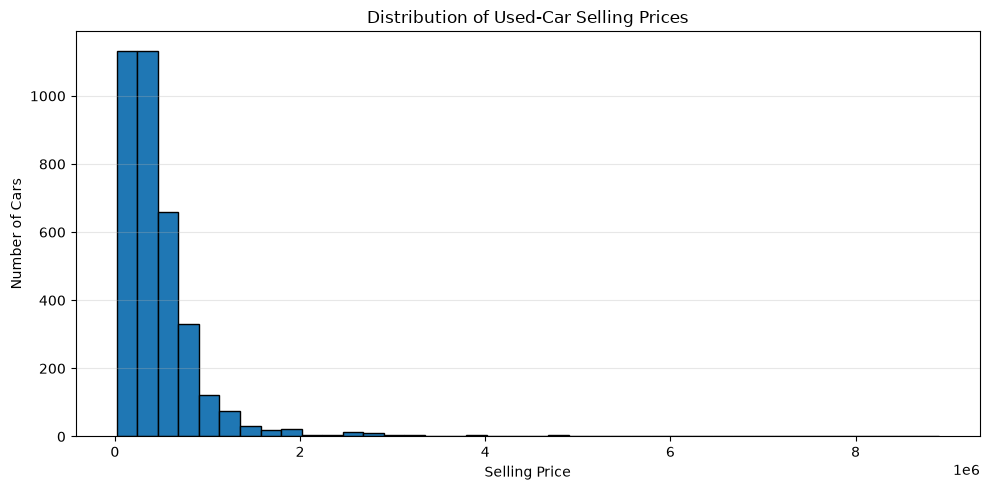

In [4]:
plt.figure(figsize=(10, 5))
plt.hist(df["selling_price"], bins=40, edgecolor="black")
plt.title("Distribution of Used-Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

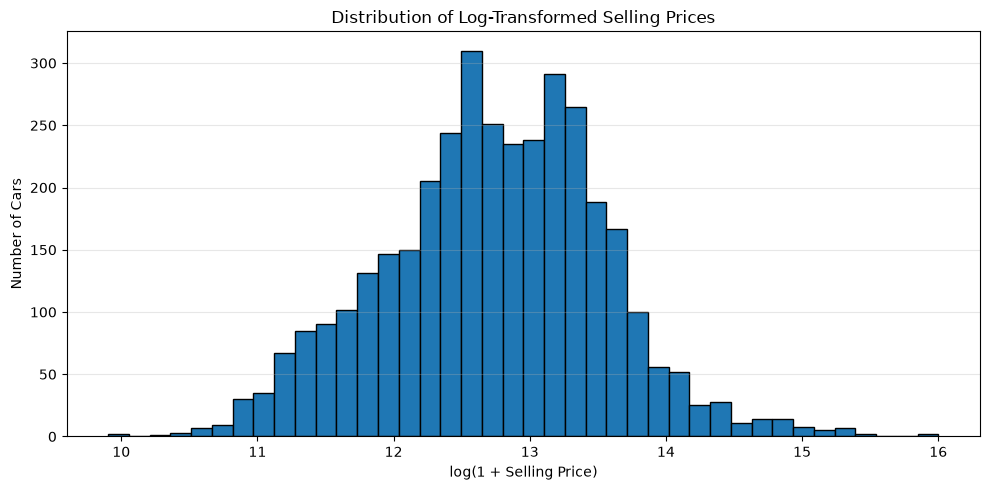

In [5]:
plt.figure(figsize=(10, 5))
plt.hist(np.log1p(df["selling_price"]), bins=40, edgecolor="black")
plt.title("Distribution of Log-Transformed Selling Prices")
plt.xlabel("log(1 + Selling Price)")
plt.ylabel("Number of Cars")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

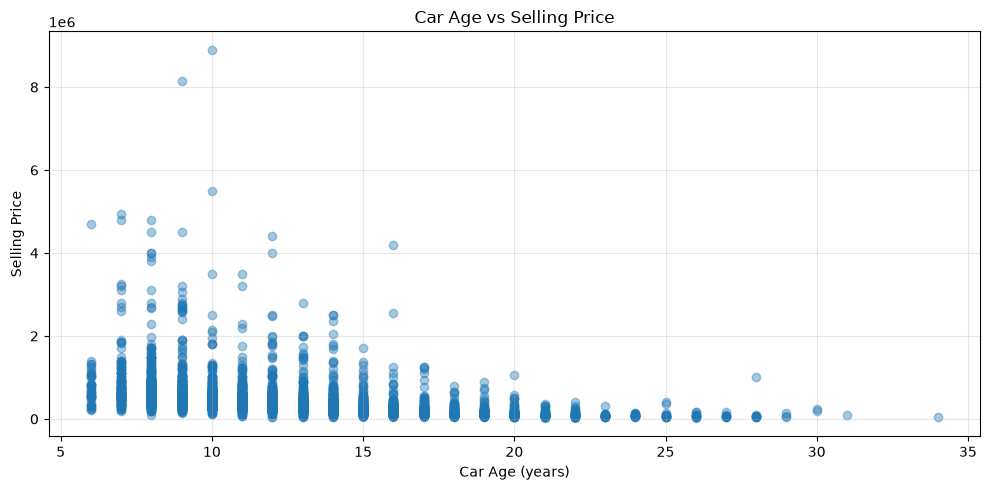

,car_age,selling_price
0,6,640000.0
1,7,650000.0
2,8,700000.0
3,9,600000.0
4,10,525000.0
5,11,450000.0
6,12,425000.0
7,13,350000.0
8,14,300000.0
9,15,250000.0


In [6]:
CURRENT_YEAR = 2026
df["car_age"] = CURRENT_YEAR - df["year"]

plt.figure(figsize=(10, 5))
plt.scatter(df["car_age"], df["selling_price"], alpha=0.4)
plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (years)")
plt.ylabel("Selling Price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(df.groupby("car_age")["selling_price"].median().reset_index())

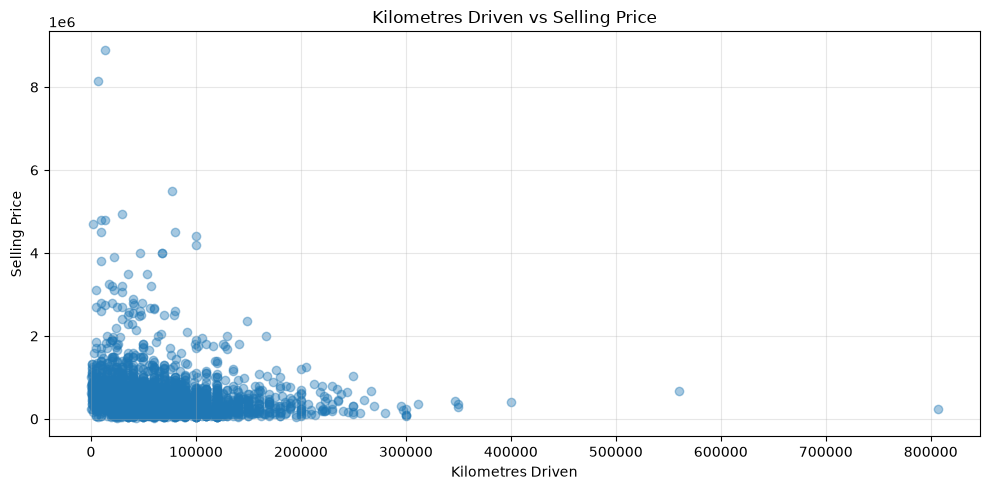

In [7]:
plt.figure(figsize=(10, 5))
plt.scatter(df["km_driven"], df["selling_price"], alpha=0.4)
plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

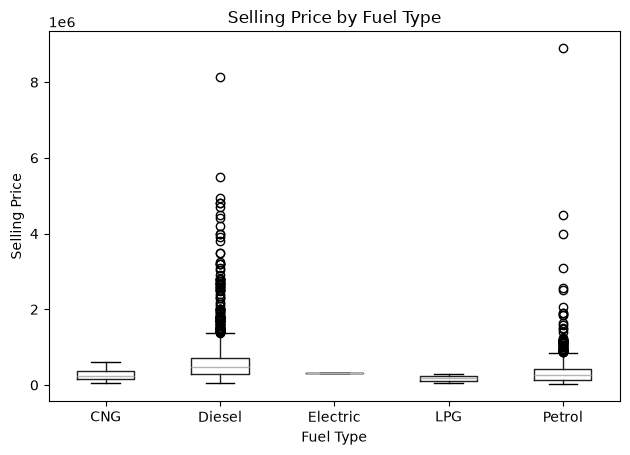

In [8]:
plt.figure(figsize=(9, 5))
df.boxplot(column="selling_price", by="fuel", grid=False)

plt.title("Selling Price by Fuel Type")
plt.suptitle("")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

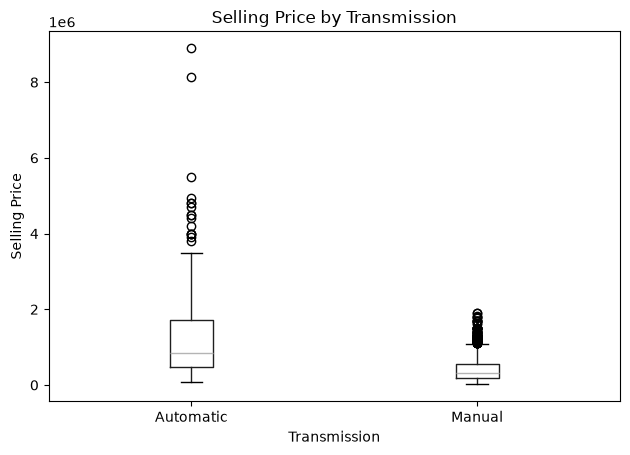

In [9]:
plt.figure(figsize=(8, 5))
df.boxplot(column="selling_price", by="transmission", grid=False)

plt.title("Selling Price by Transmission")
plt.suptitle("")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

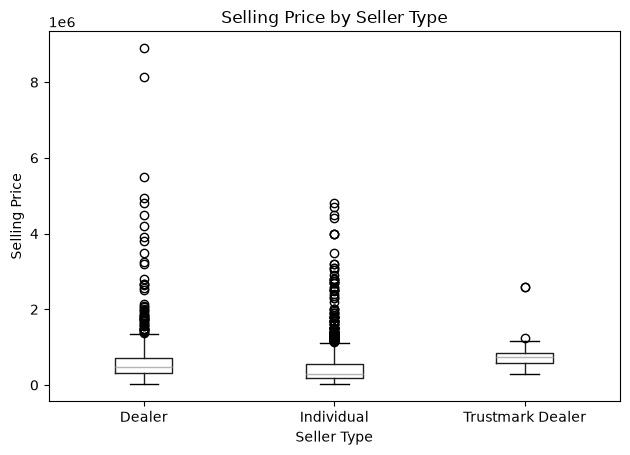

In [10]:
plt.figure(figsize=(9, 5))
df.boxplot(column="selling_price", by="seller_type", grid=False)

plt.title("Selling Price by Seller Type")
plt.suptitle("")
plt.xlabel("Seller Type")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

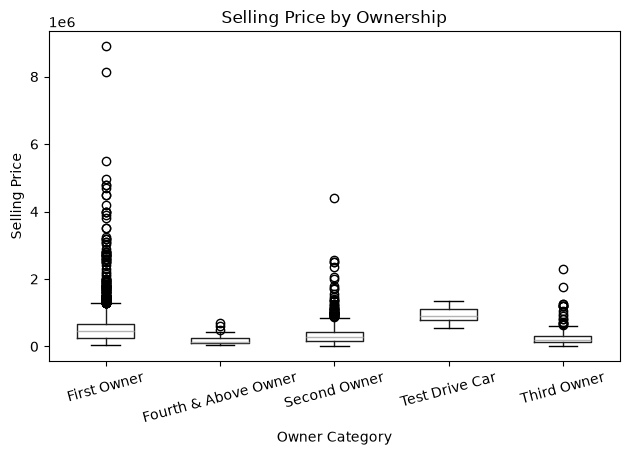

In [11]:
plt.figure(figsize=(10, 5))
df.boxplot(column="selling_price", by="owner", grid=False)

plt.title("Selling Price by Ownership")
plt.suptitle("")
plt.xlabel("Owner Category")
plt.ylabel("Selling Price")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

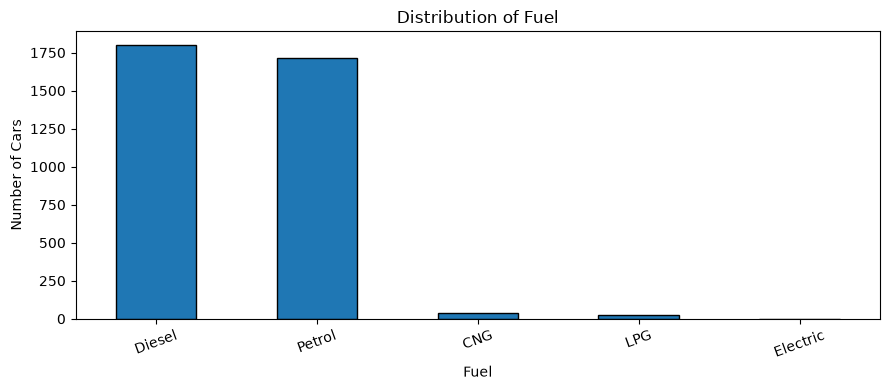

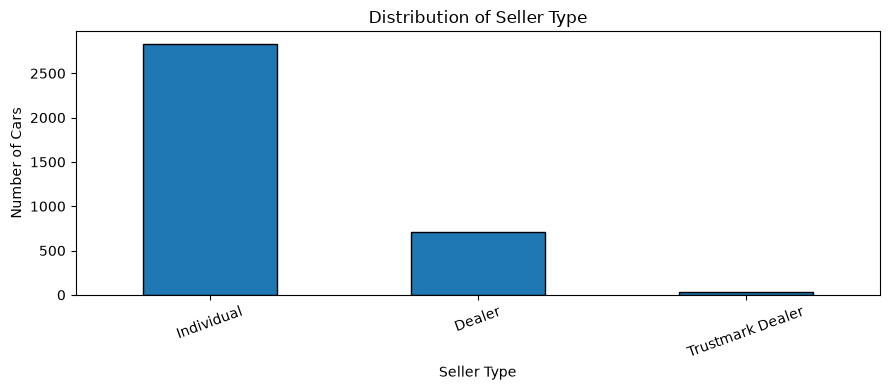

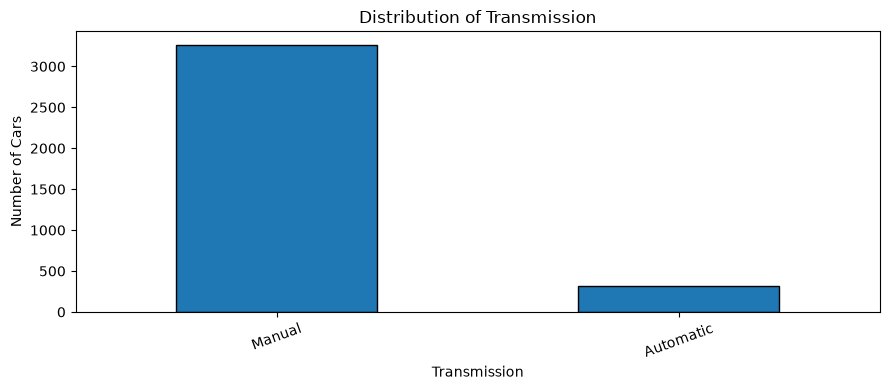

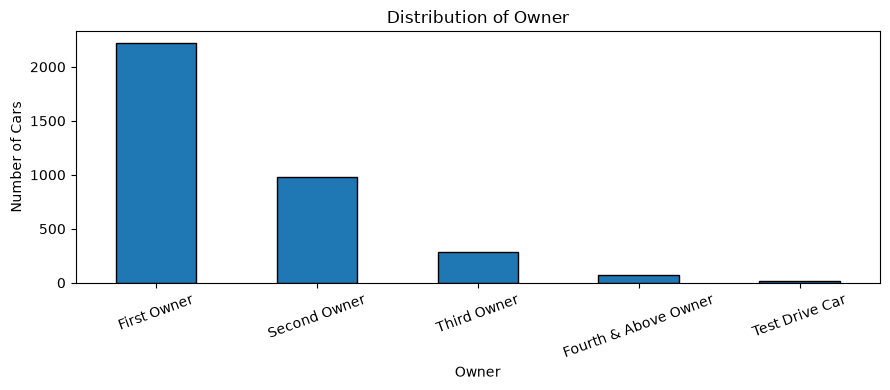

In [12]:
categorical_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

for col in categorical_columns:
    counts = df[col].value_counts()

    plt.figure(figsize=(9, 4))
    counts.plot(kind="bar", edgecolor="black")

    plt.title(f"Distribution of {col.replace('_', ' ').title()}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Number of Cars")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

Correlation Matrix:


,year,car_age,km_driven,selling_price
year,1.00000,-1.00000,-0.417490,0.424260
car_age,-1.00000,1.00000,0.417490,-0.424260
km_driven,-0.41749,0.41749,1.000000,-0.187359
selling_price,0.42426,-0.42426,-0.187359,1.000000


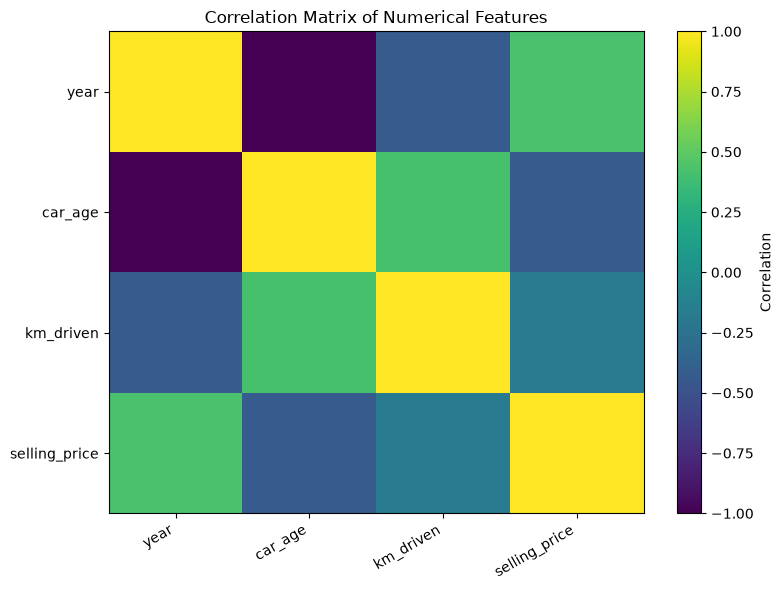

In [13]:
numeric_df = df[
    ["year", "car_age", "km_driven", "selling_price"]
]

correlation = numeric_df.corr(numeric_only=True)

print("Correlation Matrix:")
display(correlation)

plt.figure(figsize=(8, 6))
plt.imshow(correlation, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns,
           rotation=30, ha="right")
plt.yticks(range(len(correlation.index)), correlation.index)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [14]:
fuel_analysis = (
    df.groupby("fuel")["selling_price"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("median", ascending=False)
)

display(fuel_analysis)

,count,mean,median,min,max
fuel,,,,,
Diesel,1800,614001.075000,475000.0,45000,8150000
Electric,1,310000.000000,310000.0,310000,310000
Petrol,1717,335344.340128,260000.0,20000,8900000
CNG,37,273162.081081,229999.0,45000,595000
LPG,22,171818.136364,180000.0,50000,290000


,listings,median_price,average_price
name,,,
BMW 5 Series 520d Luxury Line,3,4800000.0,4.166667e+06
Toyota Fortuner 2.8 2WD AT BSIV,3,2800000.0,2.933333e+06
BMW X1 sDrive 20d xLine,3,2600000.0,2.583333e+06
Toyota Fortuner 4x2 AT,3,2595000.0,2.331667e+06
Ford Endeavour 3.2 Titanium AT 4X4,6,2387500.0,2.404167e+06
BMW 3 Series 320d Luxury Line,3,2200000.0,2.216667e+06
Toyota Innova Crysta 2.4 VX MT 8S BSIV,3,1900000.0,1.833333e+06
BMW 7 Series 730Ld,3,1700000.0,1.750000e+06
Toyota Innova Crysta 2.4 VX MT BSIV,3,1500000.0,1.523333e+06


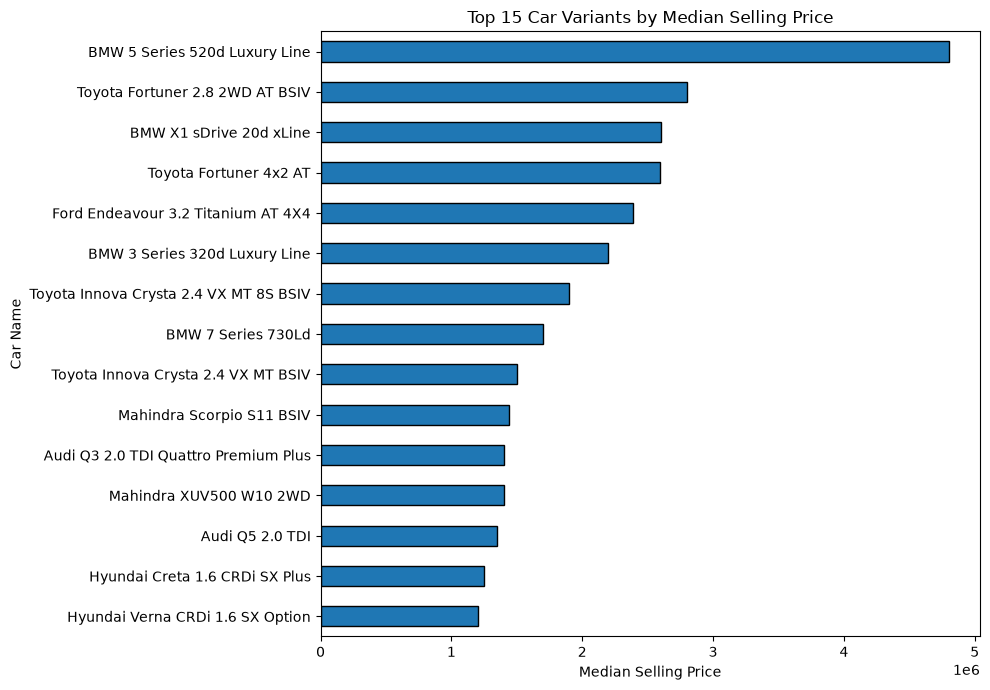

: 

In [ ]:
model_analysis = (
    df.groupby("name")
      .agg(
          listings=("selling_price", "size"),
          median_price=("selling_price", "median"),
          average_price=("selling_price", "mean")
      )
      .query("listings >= 3")
      .sort_values("median_price", ascending=False)
      .head(15)
)

display(model_analysis)

model_analysis["median_price"].sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    edgecolor="black"
)

plt.title("Top 15 Car Variants by Median Selling Price")
plt.xlabel("Median Selling Price")
plt.ylabel("Car Name")
plt.tight_layout()
plt.show()